# 11. Durable execution

## Problem

The worker disappears, but its graph checkpoint and approved write may already exist. A replacement must reclaim work without accepting a stale worker's completion or duplicating the artifact.

## Learning objectives

Persist jobs; claim and renew leases; fence stale attempts; retry only classified failures; enforce deadlines and cancellation; reconcile ambiguous committed writes.

Run top to bottom in a fresh kernel. The default path uses temporary storage and scripted inference with actual framework orchestration. Every plotted value is labelled measured, estimated or illustrative.

In [1]:
import os
from pathlib import Path
from tempfile import TemporaryDirectory
from IPython.display import display
ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "pyproject.toml").exists())
scratch = TemporaryDirectory(prefix="northstar-course-")
os.environ["MPLCONFIGDIR"] = str(Path(scratch.name) / "matplotlib")
os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGCHAIN_TRACING_V2"] = "false"
import matplotlib
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from deep_agent_lab.settings import Settings
from deep_agent_lab.courseware import diagram, bars
settings = Settings(_env_file=None, deep_lab_mode="demo", langfuse_enabled=False,
                    deep_lab_state_dir=Path(scratch.name) / "state")
assert settings.deep_lab_mode == "demo" and not settings.langfuse_enabled

## Concept explanation

## Checkpoints versus durable jobs

A checkpoint records state from which execution can resume.

Your repository already uses SQLite LangGraph checkpoints and demonstrates that a pending human review can survive recreation of the application service.

However, its asynchronous teaching example uses a process-local thread pool. That is a useful way to demonstrate concurrent work, but a thread pool does not provide durable job ownership.

The two mechanisms solve different problems.

| Mechanism             | Responsibility                                    |
| --------------------- | ------------------------------------------------- |
| LangGraph checkpoint  | Preserve graph execution state                    |
| Persistent job record | Track lifecycle, ownership, deadlines and retries |
| Worker                | Execute or resume tasks                           |
| Lease                 | Temporarily establish which worker owns execution |
| Idempotency key       | Prevent duplicate logical side effects            |
| Application database  | Persist approved business records                 |

A production-oriented design often needs all of them.

## The durable job lifecycle

The application must distinguish "the agent is running" from "the latest HTTP request is still open."

A long-running job should remain identifiable when the requesting client disconnects.

## Persistent job schema

For a focused teaching implementation, SQLite is enough. For multiple distributed workers, PostgreSQL or a dedicated durable workflow service is generally more appropriate.

The important difference from a process-local future is that this record survives worker termination.

## Claiming work safely

Multiple workers must not simply read all `QUEUED` records and start executing them.

They need an atomic claim operation.

### **Code walkthrough**

`BEGIN IMMEDIATE` serializes SQLite write transactions. Two workers using the same database cannot simultaneously acquire the same write transaction.

The lease token identifies the execution attempt.

The lease expiration permits another worker to claim a job if its previous owner disappears.

But lease expiration does **not** prove the previous worker stopped. An old worker may still be running.

That is why later state changes need a conditional check against the current lease token.

This is called *fencing*.

## Fenced completion

If the lease expires and another worker claims the job, the old worker cannot successfully complete the job using its outdated lease token.

For a complete system, lease renewal must use a similar conditional update. Long-running work should periodically check cancellation and deadlines.

A lease only protects operations that actually verify it. An unrelated external API will not automatically honor Northstar's fencing token.

## The exactly-once illusion

Consider an external side effect:

```
1. Worker calls save_brief.
2. Database commits the brief.
3. Worker crashes before recording success.
4. Job restarts.
5. Worker executes save_brief again.
```

The checkpoint may indicate that the save step needs to run again.

Therefore:

**Checkpoints do not guarantee exactly-once external effects.**

A checkpoint and a separate application database do not automatically share one atomic transaction.

The usual engineering approach is to combine at-least-once execution with idempotent effects.

For Northstar, the exact approved action should map to one stable artifact ID.

Retries can then return the existing committed result.

### **Crash scenarios**

| Failure point                       | Possible state                    | Recovery action                             |
| ----------------------------------- | --------------------------------- | ------------------------------------------- |
| Before tool execution               | No side effect                    | Retry                                       |
| During retrieval                    | Unknown read outcome              | Retry bounded read                          |
| Before write commit                 | No committed write                | Retry approved action                       |
| After write commit, before response | Write committed, status uncertain | Reconcile by idempotency key                |
| After checkpoint, before next step  | Checkpoint exists                 | Resume from persisted state                 |
| Worker lease expires                | Previous worker may still run     | Fence stale worker                          |
| Cancellation requested              | Job may be in-flight              | Stop future work and enforce write boundary |

The most important case is the ambiguous write outcome.

It should trigger reconciliation, not an assumption that the operation failed.

## Checkpoints and process restart

The repository's existing restart test is an excellent learning exercise:

1. Start a brief-generation run.
2. Reach the review interrupt.
3. Close the service and checkpoint connection.
4. Recreate them.
5. Resume the same thread with the matching review ID.
6. Confirm the approved brief exists.

The durable job extension adds lifecycle state around that existing behavior.

When restoring a job, the worker inspects both the job record and the graph state.

If the graph is waiting for review, the worker must not restart research from the beginning.

If the graph has completed but the job record is stale, the worker should reconcile the final artifact and update job status.

If the graph is incomplete, it can resume subject to retry and deadline policy.

## Retry policy and cancellation

Not every failure should be retried.

| Failure                    | Retry?                            |
| -------------------------- | --------------------------------- |
| Temporary search timeout   | Yes, within budget                |
| Invalid tool arguments     | Usually no automatic retry        |
| Permission denied          | No                                |
| Missing evidence           | Not indefinitely                  |
| Model output parse error   | Possibly one bounded repair       |
| Write with unknown outcome | Reconcile before retry            |
| Deadline exceeded          | No further work                   |
| User cancellation          | Stop work and prohibit new writes |

A useful retry policy combines maximum attempts, backoff, deadlines, and error classification.

The system must also ensure that cancellation is not simply a prompt saying "please stop."

Before every consequential write, application code should check the current cancellation and authorization state.

## Mental model

Read the following diagram as an application boundary: the model proposes actions while the runtime performs validated operations. The figure renders through Matplotlib in the notebook output.

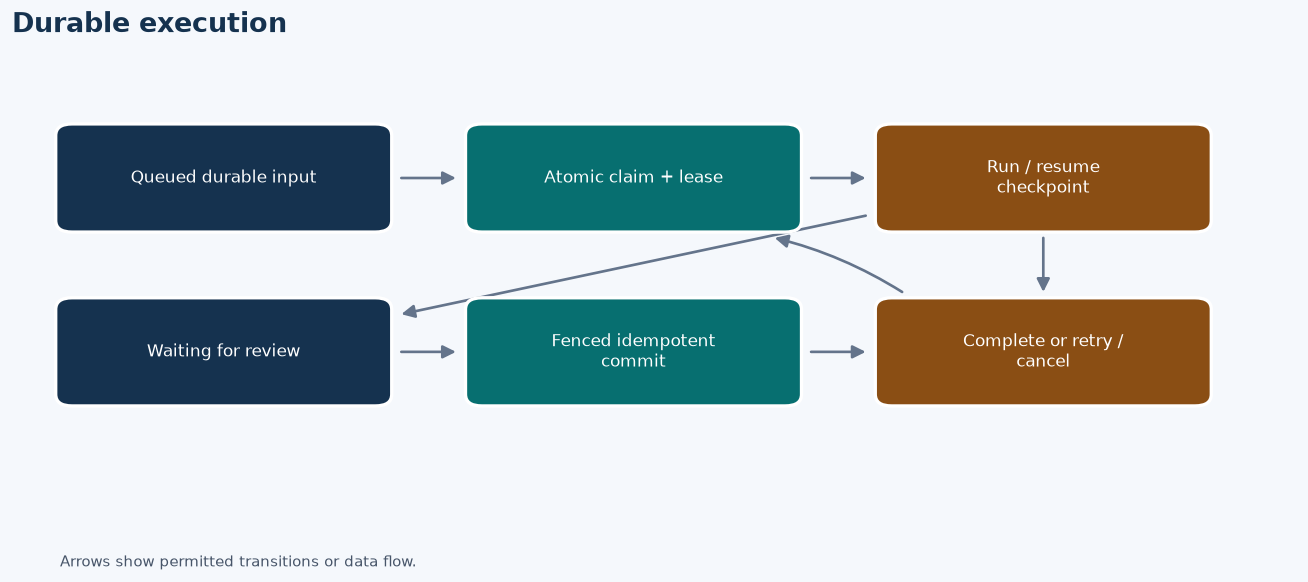

In [2]:
display(diagram('Durable execution', ['Queued durable input', 'Atomic claim + lease', 'Run / resume checkpoint', 'Waiting for review', 'Fenced idempotent commit', 'Complete or retry / cancel'], [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (2, 5), (5, 1)]))
plt.close('all')

## Implementation from scratch

Build the smallest inspectable mechanism before connecting it to the full application. The code below exposes state and checks the invariant that motivates this module.

In [3]:
import sqlite3
from contextlib import closing
from uuid import uuid4
mini_path = Path(scratch.name)/"minimal-claim.sqlite"
with closing(sqlite3.connect(mini_path)) as db,db:
    db.execute("CREATE TABLE mini_jobs (id TEXT PRIMARY KEY,status TEXT,token TEXT)")
    db.execute("INSERT INTO mini_jobs VALUES ('research','QUEUED',NULL)")

def minimal_claim(path):
    with closing(sqlite3.connect(path)) as db,db:
        db.execute("BEGIN IMMEDIATE")
        row = db.execute("SELECT id FROM mini_jobs WHERE status='QUEUED' LIMIT 1").fetchone()
        if row is None:
            return None
        token = uuid4().hex
        db.execute("UPDATE mini_jobs SET status='RUNNING',token=? WHERE id=?",(token,row[0]))
        return {"id":row[0],"token":token}

claim = minimal_claim(mini_path)
assert claim["id"] == "research" and claim["token"]
assert minimal_claim(mini_path) is None
print("A second connection cannot claim the same queued row.")
# The reusable JobStore below adds expiry, fencing, retries and cancellation.

from deep_agent_lab.jobs import JobStore,LeaseLost
from deep_agent_lab.security import Principal
now = [100.0]  # Controlled clock, not a benchmark clock.
jobs = JobStore(Path(scratch.name)/"jobs.sqlite",clock=lambda:now[0])
alice = Principal("northstar","alice")
job = jobs.submit(alice,"Research recovery authorities",job_id="durable-1",ttl=100)
first = jobs.claim(lease_seconds=5)
assert jobs.claim() is None
now[0] += 6
replacement = JobStore(jobs.path,clock=lambda:now[0]).claim(lease_seconds=10)
assert replacement["attempt"] == 2 and replacement["token"] != first["token"]
print("Attempt persisted across store recreation:",replacement["attempt"])

A second connection cannot claim the same queued row.
Attempt persisted across store recreation: 2


## Framework implementation

The following cell executes the existing Deep Agents/LangGraph application or its actual integration boundary. Any fixture ports or scripted responses are identified in the cell.

In [4]:
from deep_agent_lab.service import AgentService,RunRequest,ReviewRequest,Decision,open_checkpointer
with open_checkpointer(settings) as cp:
    service = AgentService(settings,cp)
    try:
        pending = service.run(RunRequest(prompt="Draft and save a restore brief.",thread_id="durable-graph"))
    finally:
        service.close()
# Reopen both the graph's SQLite connection and application service.
with open_checkpointer(settings) as cp:
    service = AgentService(settings,cp)
    try:
        recovered = service.inspect("durable-graph")
        assert recovered.reviews[0].id == pending.reviews[0].id
        result = service.resume("durable-graph",ReviewRequest(interrupt_id=recovered.reviews[0].id,
                                decisions=[Decision(type="approve")]))
        assert len(result.saved_brief_ids) == 1
    finally:
        service.close()
print("Checkpointed review resumed with a durable artifact.")

Checkpointed review resumed with a durable artifact.


## Code walkthrough

A checkpoint answers where graph execution stopped. A job answers who owns the work, how many attempts remain and whether it is cancelled. `BEGIN IMMEDIATE` serializes claims in this local SQLite implementation. A lease may expire while the old process is still alive; every protected transition checks the current token, deadline and lease. The capstone stores jobs in the same database as briefs so its commit guard can fence the write within the brief transaction. External services must implement their own idempotency; a checkpoint cannot make an unrelated external write exactly once.

## Interactive experiments

Renew a lease, then record a transient failure with backoff. Advance the controlled clock to observe when retry becomes available. Job attempts are bounded.

In [5]:
jobs.renew(job["id"],replacement["token"],lease_seconds=15)
jobs.fail(job["id"],replacement["token"],retryable=True,code="timeout",backoff=2)
assert jobs.claim() is None
now[0] += 3
third = jobs.claim(lease_seconds=10)
assert third["attempt"] == 3
print("Retry became available after backoff; attempt:",third["attempt"])

Retry became available after backoff; attempt: 3


## Failure experiment

Deliberately violate a contract or remove a required condition. A caught, asserted failure is an expected result; an uncaught error means this notebook has not passed.

In [6]:
try:
    jobs.transition(job["id"],first["token"],"COMPLETED",result="stale")
except LeaseLost:
    print("Expected: stale worker fenced.")
else:
    raise AssertionError("Expired worker completed")
jobs.cancel(alice,job["id"])
try:
    jobs.transition(job["id"],third["token"],"COMPLETED",result="after-cancel")
except LeaseLost:
    print("Expected: cancelled job cannot complete.")
else:
    raise AssertionError("Cancelled worker completed")

Expected: stale worker fenced.
Expected: cancelled job cannot complete.


## Verification

These assertions inspect actual state produced above. They establish the stated contracts within this lab's scope.

In [7]:
assert jobs.get(alice,job["id"])["status"] == "CANCELLED"
assert jobs.claim() is None
assert JobStore(jobs.path,clock=lambda:now[0]).get(alice,job["id"])["attempt"] == 3

## Exercise

Simulate an ambiguous write: the brief commits, but the caller loses the response. Reopen the store and retry the exact approved action. Verify one row remains. The companion recovery notebook repeats this across a separate Python process.

Try your implementation before running the complete reference solution in the next cell.

### Reference solution

Compare the implementation and assertions with your attempt.

In [8]:
from deep_agent_lab.storage import BriefStore
briefs = BriefStore(Path(scratch.name)/"ambiguous")
briefs.propose("stable-action","thread","Title","Approved content",{"BKP-7":"4"})
briefs.decide("stable-action","approve",{"BKP-7":"4"})
briefs.save_reviewed("thread","Title","Approved content",{"BKP-7":"4"})  # Response lost here.
reopened = BriefStore(Path(scratch.name)/"ambiguous")
reconciled = reopened.save_reviewed("thread","Title","Approved content",{"BKP-7":"4"})
assert reopened.get(reconciled).markdown == "Approved content"
with reopened.connect() as db:
    assert db.execute("SELECT count(*) FROM briefs").fetchone()[0] == 1

## Trade-offs and further reading

This queue is a local reference implementation. SQLite is not a distributed worker platform, and a fencing token protects only code that checks it. Long model calls need lease heartbeats at safe boundaries; cancellation prevents new commits but cannot undo an already committed effect.

[Primary source 1](https://docs.langchain.com/oss/python/langgraph/persistence) · [Primary source 2](https://docs.langchain.com/oss/python/langgraph/interrupts)

In [9]:
plt.close('all')
scratch.cleanup()
print('All offline module assertions passed.')

All offline module assertions passed.
